#### Import Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
#import dataset
df=pd.read_csv("E:\\Bus Delay Prediction ML Project\\data\\ttc-bus-delay-data-2023.csv")
df.head()

,Date,Route,Time,Day,Location,Incident,Min Delay,Min Gap,Direction,Vehicle
0,1-Jan-23,91,02:30,Sunday,WOODBINE AND MORTIMER,Diversion,81,111,NaN,8772
1,1-Jan-23,69,02:34,Sunday,WARDEN STATION,Security,22,44,S,8407
2,1-Jan-23,35,03:06,Sunday,JANE STATION,Cleaning - Unsanitary,30,60,N,1051
3,1-Jan-23,900,03:14,Sunday,KIPLING STATION,Security,17,17,NaN,3334
4,1-Jan-23,85,03:43,Sunday,MEADOWALE LOOP,Security,1,1,NaN,1559


In [3]:
#check how many rows and columns
df.shape

(50913, 10)

In [4]:
#check the values are duplicate and remove the duplicate values
df.duplicated().sum()
df=df.drop_duplicates()
df.duplicated().sum()
df.shape

(50726, 10)

In [5]:
#split date into date-month-year and time into hour and minute.
#route column takes only digit
df['Route']=pd.to_numeric(df['Route'].astype(str).str.extract(r'(\d+)', expand=False),errors='coerce')
df['Date']=pd.to_datetime(df['Date'],format='%d-%b-%y')
df['Time']=pd.to_datetime(df['Time'],format='%H:%M')
df["Day_Date"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute

In [6]:
#remove unwanted columns
df.drop(['Time','Date','Location'],axis=1,inplace=True)
df.head()


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91.0,Sunday,Diversion,81,111,NaN,8772,1,1,2023,2,30
1,69.0,Sunday,Security,22,44,S,8407,1,1,2023,2,34
2,35.0,Sunday,Cleaning - Unsanitary,30,60,N,1051,1,1,2023,3,6
3,900.0,Sunday,Security,17,17,NaN,3334,1,1,2023,3,14
4,85.0,Sunday,Security,1,1,NaN,1559,1,1,2023,3,43


In [7]:
#replace unwanted values
df.replace({'Incident':{'Road Blocked - NON-TTC Collision':'Road Blocked','Collision - TTC':'Collision','Held By':'Tire Puncher','Operations - Operator':'Operations','Cleaning - Unsanitary':'Cleaning'}},inplace=True)
df.replace({'Direction':{'B':None,'`':None,'1':None,'/':None,'L':None,'D':None,'G':None,'H':None,'7':None,str('\\'):None}},inplace=True)
df['Incident'].value_counts()
df['Vehicle']=df['Vehicle'].astype('str')
df


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91.0,Sunday,Diversion,81,111,NaN,8772,1,1,2023,2,30
1,69.0,Sunday,Security,22,44,S,8407,1,1,2023,2,34
2,35.0,Sunday,Cleaning,30,60,N,1051,1,1,2023,3,6
3,900.0,Sunday,Security,17,17,NaN,3334,1,1,2023,3,14
4,85.0,Sunday,Security,1,1,NaN,1559,1,1,2023,3,43
...,...,...,...,...,...,...,...,...,...,...,...,...
50908,84.0,Thursday,Mechanical,10,20,E,3581,30,11,2023,0,1
50909,960.0,Thursday,Mechanical,24,48,E,8390,30,11,2023,0,25
50910,116.0,Thursday,Cleaning,10,20,W,1652,30,11,2023,0,44
50911,7.0,Thursday,Operations,11,21,N,8192,30,11,2023,0,48


In [8]:
df.replace({'Vehicle':{'0':None}},inplace=True)

df.head(20)

,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91.0,Sunday,Diversion,81,111,NaN,8772,1,1,2023,2,30
1,69.0,Sunday,Security,22,44,S,8407,1,1,2023,2,34
2,35.0,Sunday,Cleaning,30,60,N,1051,1,1,2023,3,6
3,900.0,Sunday,Security,17,17,NaN,3334,1,1,2023,3,14
4,85.0,Sunday,Security,1,1,NaN,1559,1,1,2023,3,43
5,40.0,Sunday,Emergency Services,0,0,NaN,None,1,1,2023,3,47
6,336.0,Sunday,Diversion,138,168,NaN,9220,1,1,2023,3,52
7,52.0,Sunday,Emergency Services,30,60,E,3520,1,1,2023,4,25
8,24.0,Sunday,Cleaning,20,40,W,8404,1,1,2023,4,35
9,36.0,Sunday,Diversion,334,344,NaN,3524,1,1,2023,5,18


#### Check and cleaning the null values

In [9]:
#checking null values
df.isna().sum()

Route         628
Day             0
Incident        0
Min Delay       0
Min Gap         0
Direction    8826
Vehicle      2185
Day_Date        0
Month           0
Year            0
Hour            0
Minute          0
dtype: int64

In [10]:
#understanding about data
df.info()

<class 'pandas.DataFrame'>
Index: 50726 entries, 0 to 50912
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Route      50098 non-null  float64
 1   Day        50726 non-null  str    
 2   Incident   50726 non-null  str    
 3   Min Delay  50726 non-null  int64  
 4   Min Gap    50726 non-null  int64  
 5   Direction  41900 non-null  object 
 6   Vehicle    48541 non-null  object 
 7   Day_Date   50726 non-null  int32  
 8   Month      50726 non-null  int32  
 9   Year       50726 non-null  int32  
 10  Hour       50726 non-null  int32  
 11  Minute     50726 non-null  int32  
dtypes: float64(1), int32(5), int64(2), object(2), str(2)
memory usage: 4.1+ MB


In [11]:
#cleaning null values and replace it
#route column changed string into integer
df.fillna({'Direction':df['Direction'].mode()[0]},inplace=True)
df.fillna({'Route':df['Route'].median()},inplace=True)
df.fillna({'Vehicle':df['Vehicle'].mode()[0]},inplace=True)
df['Route']=df['Route'].astype('int64')
df['Vehicle']=df['Vehicle'].astype('int64')
df.head(20)


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91,Sunday,Diversion,81,111,N,8772,1,1,2023,2,30
1,69,Sunday,Security,22,44,S,8407,1,1,2023,2,34
2,35,Sunday,Cleaning,30,60,N,1051,1,1,2023,3,6
3,900,Sunday,Security,17,17,N,3334,1,1,2023,3,14
4,85,Sunday,Security,1,1,N,1559,1,1,2023,3,43
5,40,Sunday,Emergency Services,0,0,N,8339,1,1,2023,3,47
6,336,Sunday,Diversion,138,168,N,9220,1,1,2023,3,52
7,52,Sunday,Emergency Services,30,60,E,3520,1,1,2023,4,25
8,24,Sunday,Cleaning,20,40,W,8404,1,1,2023,4,35
9,36,Sunday,Diversion,334,344,N,3524,1,1,2023,5,18


In [12]:
#describe the target column
df["Min Delay"].describe()

count    50726.000000
mean        20.487777
std         51.375624
min          0.000000
25%          9.000000
50%         11.000000
75%         20.000000
max        998.000000
Name: Min Delay, dtype: float64

In [13]:
#sort the values
print("\nLargest 20 delay values:")
df.sort_values(by="Min Delay",ascending=False).head(20)


Largest 20 delay values:


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
31111,121,Wednesday,Diversion,998,101,E,8530,9,8,2023,9,5
20796,75,Monday,Diversion,997,101,N,8339,5,6,2023,7,24
7184,77,Thursday,Diversion,997,105,N,7962,23,2,2023,8,58
44280,68,Wednesday,Diversion,994,102,N,3288,25,10,2023,4,56
35694,91,Tuesday,Diversion,993,100,S,8766,5,9,2023,6,58
8467,37,Saturday,General Delay,981,981,N,8073,4,3,2023,7,17
1979,7,Wednesday,Diversion,972,982,N,8339,18,1,2023,10,49
15818,102,Friday,Diversion,962,992,N,8339,28,4,2023,7,6
3517,55,Sunday,Diversion,960,990,N,7951,29,1,2023,10,3
44966,7,Saturday,Diversion,960,969,N,9006,28,10,2023,12,22


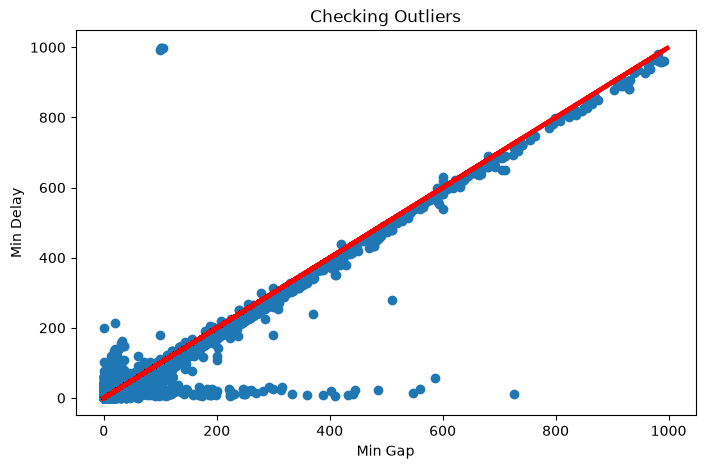

In [14]:
#checking outliers
plt.figure(figsize=(8, 5))
plt.scatter(df['Min Gap'],df['Min Delay'])
plt.plot([df['Min Gap'],df['Min Delay']],[df['Min Gap'],df['Min Delay']],linestyle='solid',linewidth=3,color='red')
plt.xlabel('Min Gap')
plt.ylabel('Min Delay')

plt.title('Checking Outliers')

plt.show()

In [15]:
#clear outliers
Q1 = df["Min Delay"].quantile(0.25)
Q3 = df["Min Delay"].quantile(0.75)

IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR


df = df[(df["Min Delay"] > upper) | (df["Min Delay"] < lower)]
#df = df[(df['Min Delay'] < lower) |(df['Min Delay'] > upper)]

print("Number of outliers:", len(df))

print("Upper limit:", upper)
print("Lower limit:", lower)
#print("High delay records:", len(df))

df.head(20)

Number of outliers: 2700
Upper limit: 36.5
Lower limit: -7.5


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91,Sunday,Diversion,81,111,N,8772,1,1,2023,2,30
6,336,Sunday,Diversion,138,168,N,9220,1,1,2023,3,52
9,36,Sunday,Diversion,334,344,N,3524,1,1,2023,5,18
11,300,Sunday,Diversion,138,148,E,3339,1,1,2023,6,4
44,87,Sunday,Diversion,50,70,E,8500,1,1,2023,11,0
127,43,Monday,Road Blocked,132,142,N,3158,2,1,2023,13,9
149,79,Monday,Diversion,120,140,S,1128,2,1,2023,18,43
150,83,Monday,Diversion,361,377,N,8339,2,1,2023,18,50
157,56,Monday,Diversion,382,408,N,8339,2,1,2023,20,46
160,47,Monday,Diversion,52,62,S,8339,2,1,2023,20,57


In [16]:
#clear null values
df.isna().sum()

Route        0
Day          0
Incident     0
Min Delay    0
Min Gap      0
Direction    0
Vehicle      0
Day_Date     0
Month        0
Year         0
Hour         0
Minute       0
dtype: int64

In [17]:
#encode categorical into numeric
from sklearn.preprocessing import LabelEncoder
inci=LabelEncoder()
direc=LabelEncoder()
day=LabelEncoder()
df['Incident']=inci.fit_transform(df['Incident'])
df['Direction']=direc.fit_transform(df['Direction'])
df['Day']=day.fit_transform(df['Day'])
df.head()


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91,3,2,81,111,1,8772,1,1,2023,2,30
6,336,3,2,138,168,1,9220,1,1,2023,3,52
9,36,3,2,334,344,1,3524,1,1,2023,5,18
11,300,3,2,138,148,0,3339,1,1,2023,6,4
44,87,3,2,50,70,0,8500,1,1,2023,11,0


In [18]:
#split input features and target(Min delay column)
x=df.drop(['Min Delay'],axis=1)
y=df['Min Delay']

#### Split the x and y as train and test data

In [19]:
from sklearn.model_selection import train_test_split
train_x,test_x,train_y,test_y=train_test_split(x,y,test_size=0.2,random_state=42)
train_x.head()

,Route,Day,Incident,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
41888,52,6,2,354,0,3577,11,10,2023,12,57
25186,116,4,2,135,1,8339,6,7,2023,6,14
41043,61,0,2,148,1,8339,6,10,2023,10,23
34450,985,1,2,80,0,3426,28,8,2023,23,46
48073,334,6,2,240,0,8785,15,11,2023,2,1


In [20]:
#copy the original data
train_x_copy=train_x.copy()
test_x_copy=test_x.copy()

#### Scaling the input features to avoid data leakage

In [21]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
train_x=sc.fit_transform(train_x)
test_x=sc.transform(test_x)

 Three models are used for this project LinearRegression,DecisionTreeRegressor and RandomForestRegressor 

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

comparing the baseline models and balance models with metrics such as mean absolute error,mean squared error and r2 score.Check mean absolute error and mean squared error as which model is lowest,also check r2 score which model get highest.

In [23]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [24]:
from sklearn.model_selection import KFold, cross_val_score
kf = KFold(n_splits=5, shuffle=True, random_state=42)

Include training data into the models

In [25]:
#baseline model
lr=LinearRegression().fit(train_x,train_y)
print("Linear Regression train_test_split score:",lr.score(train_x,train_y))
pred_y1=lr.predict(test_x)
line=pd.DataFrame({"Linear Regression": [mean_absolute_error(test_y,pred_y1), mean_squared_error(test_y,pred_y1), r2_score(test_y,pred_y1)]}, index=['MAE', 'MSE', 'R2'])
line

Linear Regression train_test_split score: 0.9382663696586786


,Linear Regression
MAE,14.892246
MSE,3360.487695
R2,0.901925


In [26]:
knr=KNeighborsRegressor().fit(train_x,train_y)
rfr=RandomForestRegressor(random_state=42,n_jobs=-1).fit(train_x_copy,train_y)

In [27]:

score=pd.DataFrame({"Trained score of models":[lr.score(train_x,train_y), knr.score(train_x,train_y), rfr.score(train_x_copy,train_y)]}, index=['Linear Regression', 'K-Nearest Neighbors Regressor', 'Random Forest'])
score

,Trained score of models
Linear Regression,0.938266
K-Nearest Neighbors Regressor,0.901604
Random Forest,0.988477


Predict the balance 2 models

In [28]:
pred_y2=knr.predict(test_x)
pred_y3=rfr.predict(test_x_copy)


Used three metrics mean absolute error,mean square error and r2 score

In [29]:
pred_df=pd.DataFrame({"Linear Regression":[mean_absolute_error(test_y,pred_y1),mean_squared_error(test_y,pred_y1),r2_score(test_y,pred_y1)],'K-Nearest Neighbors Regressor':[mean_absolute_error(test_y,pred_y2),mean_squared_error(test_y,pred_y2),r2_score(test_y,pred_y2)],'RandomForestRegressor':[mean_absolute_error(test_y,pred_y3),mean_squared_error(test_y,pred_y3),r2_score(test_y,pred_y3)]},index=['MAE','MSE','R2 Score'])
pred_df

,Linear Regression,K-Nearest Neighbors Regressor,RandomForestRegressor
MAE,14.892246,45.082222,12.851630
MSE,3360.487695,6255.441778,3326.890213
R2 Score,0.901925,0.817436,0.902905


After comparison of this three models,RandomForestRegressor is the best model.This model got MAE as 12.851630 ,MSE as 3326.890213 and R2 Score 0.902905

Got a straight line between input and target

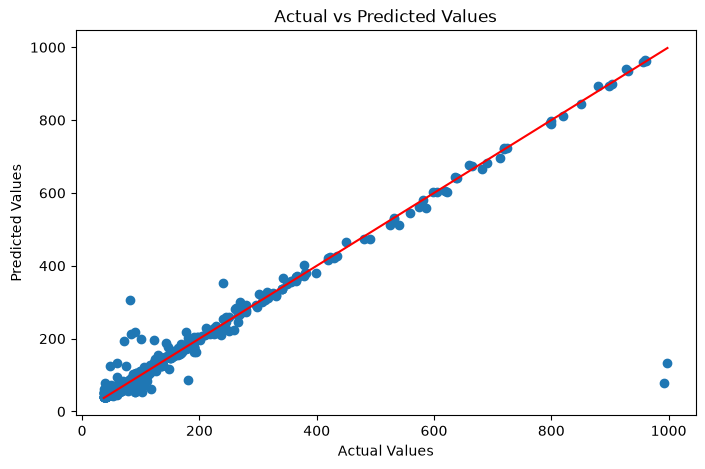

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(test_y, pred_y3)
plt.plot([test_y.min(), test_y.max()],[test_y.min(), test_y.max()],color='red')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')

plt.title('Actual vs Predicted Values')

plt.show()

Actual-The real bus delay from your dataset

Predicted-The delay predicted by the ML model

Error-Difference between actual and predicted delay

Absolute_Error-Error without the negative sign

In [31]:
compare=pd.DataFrame({'Actual':test_y,'Predicted':pred_y3})
compare['Error'] = (
    compare['Actual'] - compare['Predicted']
)

compare['Absolute_Error'] = (
    compare['Error'].abs()
)

compare.head(30)

,Actual,Predicted,Error,Absolute_Error
23453,60,63.60,-3.60,3.60
21630,123,196.23,-73.23,73.23
19601,48,50.55,-2.55,2.55
13950,43,50.92,-7.92,7.92
21695,90,81.85,8.15,8.15
8702,314,314.11,-0.11,0.11
14584,171,168.57,2.43,2.43
17706,180,202.14,-22.14,22.14
41656,100,199.27,-99.27,99.27
11499,80,74.28,5.72,5.72


Absolute_Error is large, the model made a large prediction mistake.

In [32]:
largest_errors = compare.sort_values(
    by='Absolute_Error',
    ascending=False
)

largest_errors.head(10)

,Actual,Predicted,Error,Absolute_Error
35694,993,78.27,914.73,914.73
31111,998,132.50,865.50,865.50
46852,81,306.71,-225.71,225.71
43547,90,218.84,-128.84,128.84
20632,84,212.25,-128.25,128.25
20767,72,192.82,-120.82,120.82
39307,240,351.70,-111.70,111.70
41656,100,199.27,-99.27,99.27
3569,180,85.24,94.76,94.76
38790,47,126.18,-79.18,79.18


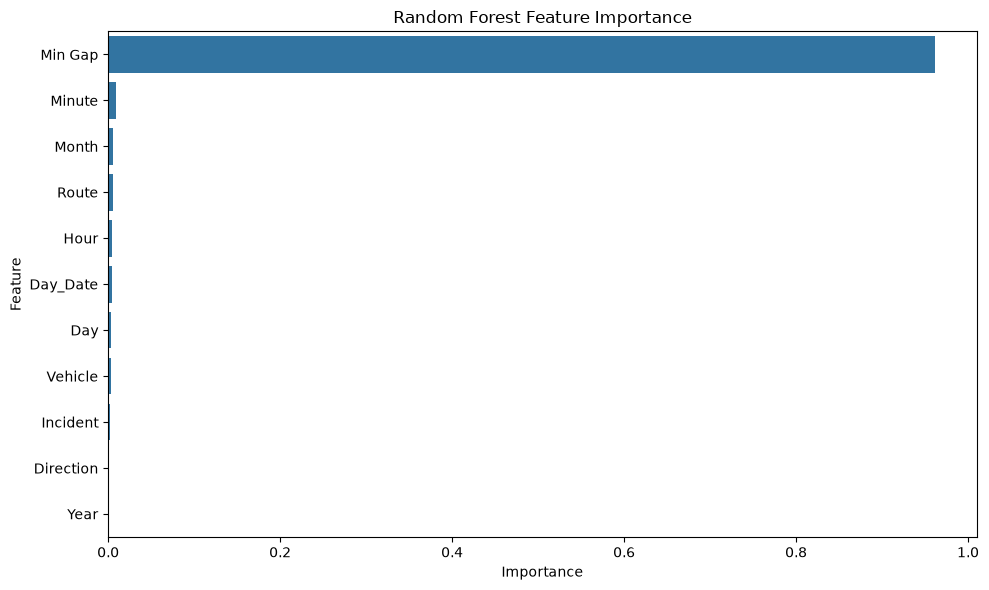

Min Gap      0.961952
Minute       0.009169
Month        0.005873
Route        0.005087
Hour         0.004650
Day_Date     0.004610
Day          0.003271
Vehicle      0.002795
Incident     0.002304
Direction    0.000290
Year         0.000000
dtype: float64

In [33]:
feature_importance = pd.Series(
    rfr.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importance.values, y=feature_importance.index)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

feature_importance

In [34]:
results = cross_val_score(lr, x, y, scoring='r2', cv=kf)
print("Cross-validation scores LinearRegression:", results)
results = cross_val_score(knr, x, y, scoring='r2', cv=kf)
print("Cross-validation scores K-Nearest Neighbors:", results)
results = cross_val_score(rfr, x, y, scoring='r2', cv=kf)
print("Cross-validation scores RandomForestRegressor:", results)

Cross-validation scores LinearRegression: [0.90192468 0.9681217  0.87240117 0.93823327 0.97466143]
Cross-validation scores K-Nearest Neighbors: [0.86659172 0.95696039 0.84209251 0.89620407 0.96412518]
Cross-validation scores RandomForestRegressor: [0.9046216  0.96903346 0.87640786 0.94016361 0.97363605]


In [35]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
param_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'copy_X': [True, False]
}
grid = GridSearchCV(lr,param_grid,cv=kf,scoring='r2')

grid.fit(train_x, train_y)

print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

best_model = grid.best_estimator_

Best Parameters: {'copy_X': True, 'fit_intercept': True, 'positive': False}
Best Score: 0.9385505433435535


In [36]:
knr_param_dist = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knr_search = GridSearchCV(
    knr,
    knr_param_dist,
    scoring='r2',
    cv=kf
)

knr_search.fit(train_x, train_y)

print("K-Nearest Neighbors best parameters:", knr_search.best_params_)
print("K-Nearest Neighbors best CV R²:", knr_search.best_score_)
best_knr_model = knr_search.best_estimator_




K-Nearest Neighbors best parameters: {'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}
K-Nearest Neighbors best CV R²: 0.8406969739304937


In [37]:
rf_param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt', 'log2']
}

rf_search = GridSearchCV(
    rfr,
    rf_param_dist,
    scoring='r2',
    cv=kf,n_jobs=-1
)

rf_search.fit(train_x_copy, train_y)

print("Random forest best parameters:", rf_search.best_params_)
print("Random forest best CV R²:", rf_search.best_score_)
best_rf_model = rf_search.best_estimator_

Random forest best parameters: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
Random forest best CV R²: 0.9445265620538814


In [38]:
score=pd.DataFrame({"Trained score of tuned models":[best_model.score(train_x,train_y), best_knr_model.score(train_x,train_y), best_rf_model.score(train_x_copy,train_y)]}, index=['Linear Regression', 'K-Nearest Neighbors Regressor', 'Random Forest Regressor'])
score

,Trained score of tuned models
Linear Regression,0.938266
K-Nearest Neighbors Regressor,1.000000
Random Forest Regressor,0.963899


In [39]:
pred_y1=best_model.predict(test_x)
pred_y2=best_knr_model.predict(test_x)
pred_y3=best_rf_model.predict(test_x_copy)

After tuning got score

In [40]:
pred_df=pd.DataFrame({"LinearRegression":[mean_absolute_error(test_y,pred_y1),mean_squared_error(test_y,pred_y1),r2_score(test_y,pred_y1)],'K-Nearest Neighbors Regressor':[mean_absolute_error(test_y,pred_y2),mean_squared_error(test_y,pred_y2),r2_score(test_y,pred_y2)],'Random Forest Regressor':[mean_absolute_error(test_y,pred_y3),mean_squared_error(test_y,pred_y3),r2_score(test_y,pred_y3)]},index=['MAE','MSE','R2 Score'])
pred_df

,LinearRegression,K-Nearest Neighbors Regressor,Random Forest Regressor
MAE,14.892246,43.973960,12.135158
MSE,3360.487695,6130.739467,3093.946999
R2 Score,0.901925,0.821075,0.909704


After hypertuned,RandomForestRegression got 0.909704 as a r2_score and MAE got 12.135158.So,this is the best model.

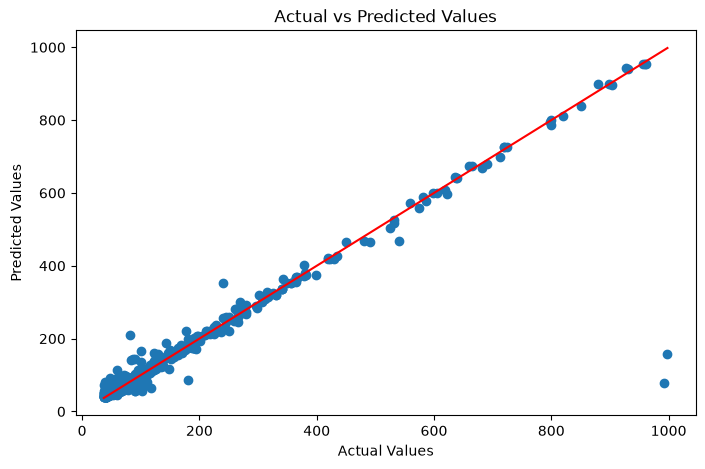

In [41]:
plt.figure(figsize=(8, 5))
plt.scatter(test_y, pred_y3)
plt.plot([test_y.min(), test_y.max()],[test_y.min(), test_y.max()],color='red')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')

plt.title('Actual vs Predicted Values')

plt.show()

In [42]:
compare=pd.DataFrame({'Actual':test_y,'Predicted':pred_y3})
compare['Error'] = (
    compare['Actual'] - compare['Predicted']
)

compare['Absolute_Error'] = (
    compare['Error'].abs()
)

compare.head(30)

,Actual,Predicted,Error,Absolute_Error
23453,60,64.724711,-4.724711,4.724711
21630,123,160.075251,-37.075251,37.075251
19601,48,53.290971,-5.290971,5.290971
13950,43,51.370752,-8.370752,8.370752
21695,90,82.946371,7.053629,7.053629
8702,314,315.334561,-1.334561,1.334561
14584,171,169.034884,1.965116,1.965116
17706,180,199.609457,-19.609457,19.609457
41656,100,166.870541,-66.870541,66.870541
11499,80,72.983458,7.016542,7.016542


In [43]:
largest_errors = compare.sort_values(
    by='Absolute_Error',
    ascending=False
)

largest_errors.head(10)

,Actual,Predicted,Error,Absolute_Error
35694,993,77.400944,915.599056,915.599056
31111,998,156.945112,841.054888,841.054888
46852,81,211.270823,-130.270823,130.270823
39307,240,354.094010,-114.094010,114.094010
3569,180,85.047294,94.952706,94.952706
38958,540,467.818290,72.181710,72.181710
41656,100,166.870541,-66.870541,66.870541
20632,84,142.524537,-58.524537,58.524537
5179,86,142.855847,-56.855847,56.855847
8984,60,114.532795,-54.532795,54.532795


In [44]:
joblib.dump(inci, 'E:\\Bus Delay Prediction ML Project\\pkl files\\label_incident.pkl')#labelencoder
joblib.dump(direc, 'E:\\Bus Delay Prediction ML Project\\pkl files\\label_direction.pkl')#labelencoder day
joblib.dump(day, 'E:\\Bus Delay Prediction ML Project\\pkl files\\label_day.pkl')#labelencoder day

['E:\\Bus Delay Prediction ML Project\\pkl files\\label_day.pkl']

In [45]:
joblib.dump(sc,'E:\\Bus Delay Prediction ML Project\\pkl files\\scaled.pkl')#standard scaler

['E:\\Bus Delay Prediction ML Project\\pkl files\\scaled.pkl']

In [46]:
joblib.dump(best_rf_model,'E:\\Bus Delay Prediction ML Project\\pkl files\\randomforestregressor.pkl')#randomforestregressor model
joblib.dump(best_model,'E:\\Bus Delay Prediction ML Project\\pkl files\\linearregressor.pkl')#linearregressor model
joblib.dump(best_knr_model,'E:\\Bus Delay Prediction ML Project\\pkl files\\kneighborsregressor.pkl')#kneighborsregressor model

['E:\\Bus Delay Prediction ML Project\\pkl files\\kneighborsregressor.pkl']